This section sets random seeds, defines relative paths, and loads all datasets used in the BERT experiment.

In [ ]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split

# =========================
# Setup
# =========================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Assume the notebook is run inside CODE/
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT.parent / "MISC" / "data"
OUTPUT_DIR = PROJECT_ROOT.parent / "MISC" / "outputs"
MODEL_DIR = PROJECT_ROOT.parent / "MISC" / "saved_model"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("Model directory:", MODEL_DIR)

# =========================
# Data loading function
# =========================
def load_data(file_path):
    encodings = ["utf-8", "latin1", "cp1252", "ISO-8859-1"]
    last_error = None

    for enc in encodings:
        try:
            df = pd.read_csv(file_path, encoding=enc)
            print(f"Loaded {file_path.name} with encoding: {enc}")
            df = df[["cleaned_text", "toxic"]].dropna().copy()
            df["cleaned_text"] = df["cleaned_text"].astype(str)
            df["toxic"] = df["toxic"].astype(int)
            return df
        except Exception as e:
            last_error = e

    raise ValueError(f"Could not read {file_path}. Last error: {last_error}")

# =========================
# File paths
# =========================
train_path = DATA_DIR / "train.csv"
val_path = DATA_DIR / "val.csv"
test_path = DATA_DIR / "test.csv"
manual_path = DATA_DIR / "manual_annotation_200.csv"

required_files = [train_path, val_path, test_path, manual_path]
for file in required_files:
    if not file.exists():
        raise FileNotFoundError(
            f"Missing file: {file}\n"
            f"Please make sure the datasets are placed in ../MISC/data/ relative to the CODE folder."
        )

# =========================
# Load datasets
# =========================
train_df = load_data(train_path)
val_df = load_data(val_path)
test_df = load_data(test_path)
manual_df = load_data(manual_path)

print("Main training set size:", len(train_df))
print("Validation set size:", len(val_df))
print("Test set size:", len(test_df))
print("Manual annotation dataset size:", len(manual_df))

Project root: /content
Data directory: /MISC/data
Output directory: /MISC/outputs
Model directory: /MISC/saved_model
Loaded train.csv with encoding: utf-8
Loaded val.csv with encoding: utf-8
Loaded test.csv with encoding: utf-8
Loaded manual_annotation_200.csv with encoding: latin1
Main training set size: 51128
Validation set size: 6391
Test set size: 6391
Manual annotation dataset size: 232


This section splits the manually annotated dataset into a small training augmentation set and a held-out evaluation set.

In [ ]:
# Split the manual dataset into:
# 1) manual_train_df: used to augment training
# 2) manual_eval_df: held-out manual evaluation set
manual_train_df, manual_eval_df = train_test_split(
    manual_df,
    test_size=0.25,
    random_state=SEED,
    stratify=manual_df["toxic"]
)

print("Manual training subset size:", len(manual_train_df))
print("Manual held-out evaluation subset size:", len(manual_eval_df))

print("\nManual training subset label distribution:")
print(manual_train_df["toxic"].value_counts())

print("\nManual held-out evaluation subset label distribution:")
print(manual_eval_df["toxic"].value_counts())

Manual training subset size: 174
Manual held-out evaluation subset size: 58

Manual training subset label distribution:
toxic
0    108
1     66
Name: count, dtype: int64

Manual held-out evaluation subset label distribution:
toxic
0    36
1    22
Name: count, dtype: int64


This section augments the original training set by adding part of the manually labelled data.

In [ ]:
# Add the manual training subset into the main training set
train_df_augmented = pd.concat([train_df, manual_train_df], ignore_index=True)

print("Original training set size:", len(train_df))
print("Augmented training set size:", len(train_df_augmented))

print("\nAugmented training label distribution:")
print(train_df_augmented["toxic"].value_counts())

Original training set size: 51128
Augmented training set size: 51302

Augmented training label distribution:
toxic
0    46508
1     4794
Name: count, dtype: int64


This section converts pandas data into Hugging Face datasets and loads the BERT tokenizer.

In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer

# Convert pandas DataFrames to Hugging Face Datasets
train_dataset = Dataset.from_pandas(train_df_augmented, preserve_index=False)
val_dataset = Dataset.from_pandas(val_df, preserve_index=False)
test_dataset = Dataset.from_pandas(test_df, preserve_index=False)
manual_eval_dataset = Dataset.from_pandas(manual_eval_df, preserve_index=False)

print("Train dataset:", train_dataset)
print("Validation dataset:", val_dataset)
print("Test dataset:", test_dataset)
print("Manual held-out evaluation dataset:", manual_eval_dataset)

# Load the BERT tokenizer
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Test the tokenizer on one example
sample_text = train_df_augmented["cleaned_text"].iloc[0]
sample_tokens = tokenizer(sample_text)

print("\nSample text:")
print(sample_text)
print("\nTokenized example:")
print(sample_tokens)

Train dataset: Dataset({
    features: ['cleaned_text', 'toxic'],
    num_rows: 51302
})
Validation dataset: Dataset({
    features: ['cleaned_text', 'toxic'],
    num_rows: 6391
})
Test dataset: Dataset({
    features: ['cleaned_text', 'toxic'],
    num_rows: 6391
})
Manual held-out evaluation dataset: Dataset({
    features: ['cleaned_text', 'toxic'],
    num_rows: 58
})

Sample text:
i am trying to get an article up that covers all of ldi's activities and links to both supporters and opponents of those activities. in a previous incarnation of this page, before it was nuked, i included quite a few links, pro and con. it is my understanding that there is to be some sort of discussion before nuking articles, and i can't even find out who has been doing the deletion! what sort of recourse do i have?

Tokenized example:
{'input_ids': [101, 1045, 2572, 2667, 2000, 2131, 2019, 3720, 2039, 2008, 4472, 2035, 1997, 25510, 2072, 1005, 1055, 3450, 1998, 6971, 2000, 2119, 6793, 1998, 7892, 1997,

This section tokenizes all text samples so they can be used as inputs to the BERT classification model.

In [ ]:
# Define a function to tokenize text examples
def tokenize_function(examples):
    return tokenizer(
        examples["cleaned_text"],
        truncation=True,
        max_length=128
    )

# Apply tokenization to the full datasets
train_dataset = train_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)
manual_eval_dataset = manual_eval_dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/51302 [00:00<?, ? examples/s]

Map:   0%|          | 0/6391 [00:00<?, ? examples/s]

Map:   0%|          | 0/6391 [00:00<?, ? examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

This section renames the target column to 'labels' and keeps only the fields required for model training.

In [ ]:
# Rename the target column from "toxic" to "labels"
train_dataset = train_dataset.rename_column("toxic", "labels")
val_dataset = val_dataset.rename_column("toxic", "labels")
test_dataset = test_dataset.rename_column("toxic", "labels")
manual_eval_dataset = manual_eval_dataset.rename_column("toxic", "labels")

# Keep only the columns needed for BERT training
keep_columns = ["input_ids", "attention_mask", "labels"]

train_dataset = train_dataset.remove_columns(
    [col for col in train_dataset.column_names if col not in keep_columns]
)
val_dataset = val_dataset.remove_columns(
    [col for col in val_dataset.column_names if col not in keep_columns]
)
test_dataset = test_dataset.remove_columns(
    [col for col in test_dataset.column_names if col not in keep_columns]
)
manual_eval_dataset = manual_eval_dataset.remove_columns(
    [col for col in manual_eval_dataset.column_names if col not in keep_columns]
)

print("Final train columns:", train_dataset.column_names)
print("Final validation columns:", val_dataset.column_names)
print("Final test columns:", test_dataset.column_names)
print("Final manual evaluation columns:", manual_eval_dataset.column_names)

Final train columns: ['labels', 'input_ids', 'attention_mask']
Final validation columns: ['labels', 'input_ids', 'attention_mask']
Final test columns: ['labels', 'input_ids', 'attention_mask']
Final manual evaluation columns: ['labels', 'input_ids', 'attention_mask']


This section loads the pre-trained BERT classifier and defines the evaluation metrics used in the project.

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding

# Load the BERT sequence classification model
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Create a data collator for dynamic padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Define evaluation metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )
    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


This section computes class weights automatically from the training data to reduce the impact of class imbalance during training.

In [ ]:
# Compute class weights automatically from the augmented training set
label_counts = train_df_augmented["toxic"].value_counts().sort_index()
total_samples = len(train_df_augmented)
num_classes = len(label_counts)

class_weights = torch.tensor(
    [total_samples / (num_classes * label_counts[i]) for i in range(num_classes)],
    dtype=torch.float
)

print("Class counts:")
print(label_counts)
print("Computed class weights:", class_weights)

Class counts:
toxic
0    46508
1     4794
Name: count, dtype: int64
Computed class weights: tensor([0.5515, 5.3506])


This section defines a custom Trainer that uses weighted cross-entropy loss for imbalanced classification.

In [ ]:
import torch.nn as nn
from transformers import Trainer

# Define a custom Trainer with weighted loss
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        weights = class_weights.to(logits.device)
        loss_fct = nn.CrossEntropyLoss(weight=weights)
        loss = loss_fct(logits, labels)

        return (loss, outputs) if return_outputs else loss

This section defines the training setup.
F1-score is used to select the best model because the dataset is imbalanced.

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "bert_augmented_weighted_results"),
    num_train_epochs=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)

print(training_args)

TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=False,
eval_steps=None,
eval_strategy=IntervalStrategy.EPOCH,
eval_use_gather_object=Fals

This section builds the Trainer object that will be used for model fine-tuning and evaluation.

In [ ]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print("Weighted Trainer is ready.")
print(trainer)
print("Training columns:", trainer.train_dataset.column_names)

Weighted Trainer is ready.
Training columns: ['labels', 'input_ids', 'attention_mask']


This section fine-tunes the BERT model on the augmented training set.

In [ ]:
# Start training
train_result = trainer.train()

print("Training finished.")
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.377840,0.466478,0.962134,0.861284,0.703892,0.774674
2,0.231134,0.367211,0.960257,0.772213,0.808799,0.790083


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

Training finished.
TrainOutput(global_step=6414, training_loss=0.3044866473272578, metrics={'train_runtime': 914.5271, 'train_samples_per_second': 112.194, 'train_steps_per_second': 7.013, 'total_flos': 6695641914580800.0, 'train_loss': 0.3044866473272578, 'epoch': 2.0})


This section evaluates the trained model on the validation set, test set, and held-out manual dataset.

In [ ]:
# Evaluate on the validation set
val_results = trainer.evaluate(eval_dataset=val_dataset)
print("Validation results:")
print(val_results)

# Evaluate on the test set
test_results = trainer.evaluate(eval_dataset=test_dataset)
print("\nTest results:")
print(test_results)

# Evaluate on the held-out manual annotation dataset
manual_results = trainer.evaluate(eval_dataset=manual_eval_dataset)
print("\nManual held-out evaluation results:")
print(manual_results)

Validation results:
{'eval_loss': 0.3672114908695221, 'eval_accuracy': 0.9602566108590205, 'eval_precision': 0.7722132471728594, 'eval_recall': 0.8087986463620981, 'eval_f1': 0.7900826446280992, 'eval_runtime': 13.3902, 'eval_samples_per_second': 477.288, 'eval_steps_per_second': 29.872, 'epoch': 2.0}

Test results:
{'eval_loss': 0.35479357838630676, 'eval_accuracy': 0.9582225003911751, 'eval_precision': 0.7547169811320755, 'eval_recall': 0.8121827411167513, 'eval_f1': 0.78239608801956, 'eval_runtime': 14.545, 'eval_samples_per_second': 439.396, 'eval_steps_per_second': 27.501, 'epoch': 2.0}

Manual held-out evaluation results:
{'eval_loss': 1.9339810609817505, 'eval_accuracy': 0.8275862068965517, 'eval_precision': 0.875, 'eval_recall': 0.6363636363636364, 'eval_f1': 0.7368421052631579, 'eval_runtime': 0.0985, 'eval_samples_per_second': 589.012, 'eval_steps_per_second': 40.622, 'epoch': 2.0}


 This section saves the fine-tuned model and tokenizer for later testing or demo use.

In [ ]:
# Save the final best model and tokenizer
save_dir = MODEL_DIR / "bert_augmented_weighted_model"

trainer.save_model(save_dir)
tokenizer.save_pretrained(save_dir)

print(f"\nFinal model saved to: {save_dir}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Final model saved to: /MISC/saved_model/bert_augmented_weighted_model


This section shows detailed test-set performance and visualises prediction errors using a confusion matrix.

Test Accuracy: 0.9582225003911751
Test Precision: 0.7547169811320755
Test Recall: 0.8121827411167513
Test F1-score: 0.78239608801956


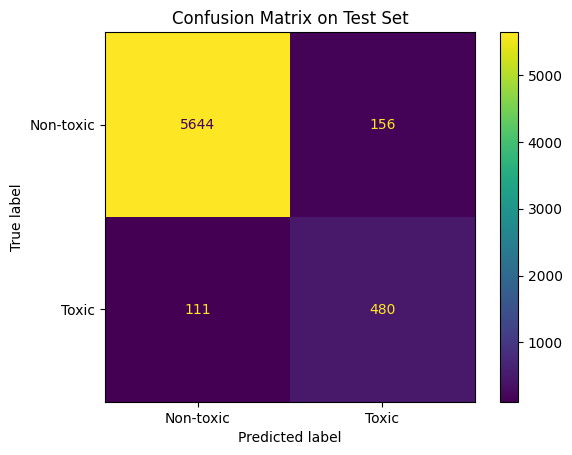

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Get predictions on the test set
pred_output = trainer.predict(test_dataset)

# Predicted labels
y_pred = np.argmax(pred_output.predictions, axis=1)

# True labels
y_true = np.array(test_dataset["labels"])

# Compute metrics again from predictions
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(y_true, y_pred, zero_division=0)
test_recall = recall_score(y_true, y_pred, zero_division=0)
test_f1 = f1_score(y_true, y_pred, zero_division=0)

print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-toxic", "Toxic"])
disp.plot()
plt.title("Confusion Matrix on Test Set")
plt.show()

In [61]:
# Misclassified examples on test set
test_results_df = pd.DataFrame({
    "cleaned_text": test_df["cleaned_text"].reset_index(drop=True),
    "true_label": y_true,
    "pred_label": y_pred
})

test_misclassified = test_results_df[
    test_results_df["true_label"] != test_results_df["pred_label"]
].copy()

test_false_positives = test_misclassified[
    (test_misclassified["true_label"] == 0) & (test_misclassified["pred_label"] == 1)
].copy()

test_false_negatives = test_misclassified[
    (test_misclassified["true_label"] == 1) & (test_misclassified["pred_label"] == 0)
].copy()

print("\nNumber of misclassified examples on test set:", len(test_misclassified))
print("Number of false positives on test set:", len(test_false_positives))
print("Number of false negatives on test set:", len(test_false_negatives))

print("\nTest Set - False Positives:")
for i, row in test_false_positives.head(5).iterrows():
    print("=" * 100)
    print(f"Index: {i}")
    print(f"Text: {row['cleaned_text']}")
    print(f"True label: {row['true_label']}")
    print(f"Pred label: {row['pred_label']}")

print("\nTest Set - False Negatives:")
for i, row in test_false_negatives.head(5).iterrows():
    print("=" * 100)
    print(f"Index: {i}")
    print(f"Text: {row['cleaned_text']}")
    print(f"True label: {row['true_label']}")
    print(f"Pred label: {row['pred_label']}")


Number of misclassified examples on test set: 267
Number of false positives on test set: 156
Number of false negatives on test set: 111

Test Set - False Positives:
Index: 12
Text: khadr killed a us military medic both micheal rempel and peter kent had every right to inform americans of this deal that trudeau authorized.
True label: 0
Pred label: 1
Index: 15
Text: to think that they dug out a big ditch on sacred indian land, and then pooped out feces and pissed urine on this holy ground for a full month. seems to me that they deserve more than a year in jail for doing that.
True label: 0
Pred label: 1
Index: 21
Text: this is absolutely ridiculous. i mean people actually wasting their time to discuss such a nonsensical thing is just beyond me. i know its a free country and all that and people have the right to choose how they want to spend their time, but this is taking it too far.
True label: 0
Pred label: 1
Index: 97
Text: connell66 should be blocked he just does it randomly. i can't

 This section evaluates generalisation on the manually annotated held-out set.

Manual Accuracy: 0.8275862068965517
Manual Precision: 0.875
Manual Recall: 0.6363636363636364
Manual F1-score: 0.7368421052631579


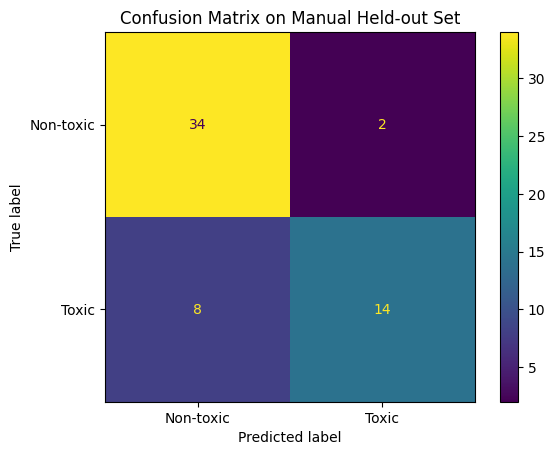

In [ ]:
# Get predictions on the manual held-out dataset
manual_pred_output = trainer.predict(manual_eval_dataset)

# Predicted labels
manual_y_pred = np.argmax(manual_pred_output.predictions, axis=1)

# True labels
manual_y_true = np.array(manual_eval_dataset["labels"])

# Compute metrics
manual_accuracy = accuracy_score(manual_y_true, manual_y_pred)
manual_precision = precision_score(manual_y_true, manual_y_pred, zero_division=0)
manual_recall = recall_score(manual_y_true, manual_y_pred, zero_division=0)
manual_f1 = f1_score(manual_y_true, manual_y_pred, zero_division=0)

print("Manual Accuracy:", manual_accuracy)
print("Manual Precision:", manual_precision)
print("Manual Recall:", manual_recall)
print("Manual F1-score:", manual_f1)

# Confusion matrix
manual_cm = confusion_matrix(manual_y_true, manual_y_pred)
manual_disp = ConfusionMatrixDisplay(
    confusion_matrix=manual_cm,
    display_labels=["Non-toxic", "Toxic"]
)
manual_disp.plot()
plt.title("Confusion Matrix on Manual Held-out Set")
plt.show()

In [62]:
# Misclassified examples on manual held-out set
manual_results_df = pd.DataFrame({
    "cleaned_text": manual_eval_df["cleaned_text"].reset_index(drop=True),
    "true_label": manual_y_true,
    "pred_label": manual_y_pred
})

# Keep only misclassified examples
manual_misclassified_df = manual_results_df[
    manual_results_df["true_label"] != manual_results_df["pred_label"]
].copy()

print("Number of misclassified examples:", len(manual_misclassified_df))

# False positives
false_positives = manual_misclassified_df[
    (manual_misclassified_df["true_label"] == 0) &
    (manual_misclassified_df["pred_label"] == 1)
].copy()

# False negatives
false_negatives = manual_misclassified_df[
    (manual_misclassified_df["true_label"] == 1) &
    (manual_misclassified_df["pred_label"] == 0)
].copy()

print("Number of false positives:", len(false_positives))
print("Number of false negatives:", len(false_negatives))

print("\nFalse Positives:")
for i, row in false_positives.head(5).iterrows():
    print("=" * 100)
    print(f"Index: {i}")
    print(f"Text: {row['cleaned_text']}")
    print(f"True label: {row['true_label']}")
    print(f"Pred label: {row['pred_label']}")

print("\nFalse Negatives:")
for i, row in false_negatives.head(5).iterrows():
    print("=" * 100)
    print(f"Index: {i}")
    print(f"Text: {row['cleaned_text']}")
    print(f"True label: {row['true_label']}")
    print(f"Pred label: {row['pred_label']}")

Number of misclassified examples: 10
Number of false positives: 2
Number of false negatives: 8

False Positives:
Index: 0
Text: Bro og Tydus is so flipping funny
True label: 0
Pred label: 1
Index: 13
Text: My god!!! the comedian absolutely murdered the crowd tonight.
True label: 0
Pred label: 1

False Negatives:
Index: 7
Text: A thief always says that he did not steal, a rapist always says that he did not rape, now she is saying that she did not even know Epstein, now only God knows what is the truth in this.
True label: 1
Pred label: 0
Index: 8
Text: I AGREE VERY MUCH, MR. PRESIDENT, PLEASE SPEED UP LIKE LIGHTNING BECAUSE THE SYSTEM IS DECLINED & FULL OF MANIPULATION AND LIES. IT MUST BE REPLACED WITH A HEALTHY SYSTEM FULL OF HONESTY ACCORDING TO THE BIBLE.
True label: 1
Pred label: 0
Index: 15
Text: The banter between Trump and Little Marco was epic. Marco Rubio is big Marco now, doing a awesome job.
True label: 1
Pred label: 0
Index: 37
Text: This IS obviously AI. Your TDS is showin

This section summarises the final results across all evaluation sets and saves them as a CSV file for reporting.

In [57]:
results_table = pd.DataFrame({
    "Model": [
        "BERT-augmented-weighted",
        "BERT-augmented-weighted",
        "BERT-augmented-weighted"
    ],
    "Dataset": [
        "Validation",
        "Test",
        "Manual held-out"
    ],
    "Accuracy": [
        val_results["eval_accuracy"],
        test_results["eval_accuracy"],
        manual_accuracy
    ],
    "Precision": [
        val_results["eval_precision"],
        test_results["eval_precision"],
        manual_precision
    ],
    "Recall": [
        val_results["eval_recall"],
        test_results["eval_recall"],
        manual_recall
    ],
    "F1-score": [
        val_results["eval_f1"],
        test_results["eval_f1"],
        manual_f1
    ]
})

print(results_table.round(4))

results_table.round(4).to_csv(OUTPUT_DIR / "bert_results_summary.csv", index=False)
print("\nResults table saved to:", OUTPUT_DIR / "bert_results_summary.csv")

                     Model          Dataset  Accuracy  Precision  Recall  \
0  BERT-augmented-weighted       Validation    0.9603     0.7722  0.8088   
1  BERT-augmented-weighted             Test    0.9582     0.7547  0.8122   
2  BERT-augmented-weighted  Manual held-out    0.8276     0.8750  0.6364   

   F1-score  
0    0.7901  
1    0.7824  
2    0.7368  

Results table saved to: /MISC/outputs/bert_results_summary.csv


This section provides a simple single-text prediction example to demonstrate how the fine-tuned BERT model can be used in practice.

In [ ]:
import torch.nn.functional as F

def predict_toxicity(text, model, tokenizer, max_length=128):
    model.eval()
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=max_length
    )

    device = model.device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

    label_map = {0: "Non-toxic", 1: "Toxic"}
    return {
        "text": text,
        "predicted_label": label_map[pred],
        "non_toxic_probability": probs[0][0].item(),
        "toxic_probability": probs[0][1].item(),
    }

example_text = "You are such an idiot."
result = predict_toxicity(example_text, trainer.model, tokenizer)

print("Single-text prediction example:")
print(result)

Single-text prediction example:
{'text': 'You are such an idiot.', 'predicted_label': 'Toxic', 'non_toxic_probability': 0.0001565906568430364, 'toxic_probability': 0.9998433589935303}


# Gradio Demo Interface

This section creates a simple Gradio demo for the fine-tuned BERT toxic comment classifier.

### What this section does
- writes the demo code into `app.py`
- loads the saved tokenizer and fine-tuned model
- defines a prediction function for new user input
- launches a Gradio interface for interactive testing

### Demo function
Users can enter a comment and view:
- the predicted label (`Toxic` or `Non-toxic`)
- the non-toxic probability
- the toxic probability


In [ ]:
app_code = r'''
from pathlib import Path
import torch
import torch.nn.functional as F
import gradio as gr
from transformers import AutoTokenizer, AutoModelForSequenceClassification

PROJECT_ROOT = Path.cwd()
MODEL_DIR = PROJECT_ROOT.parent / "MISC" / "saved_model" / "bert_augmented_weighted_model"

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

def predict_toxicity(text):
    if not text or not text.strip():
        return "Please enter some text.", "", ""

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=1)[0]

    non_toxic_prob = float(probs[0])
    toxic_prob = float(probs[1])
    pred_label = "Toxic" if toxic_prob > non_toxic_prob else "Non-toxic"

    return (
        pred_label,
        f"{non_toxic_prob:.4f}",
        f"{toxic_prob:.4f}"
    )

demo = gr.Interface(
    fn=predict_toxicity,
    inputs=gr.Textbox(lines=4, placeholder="Enter a comment here..."),
    outputs=[
        gr.Textbox(label="Predicted Label"),
        gr.Textbox(label="Non-toxic Probability"),
        gr.Textbox(label="Toxic Probability")
    ],
    title="Toxic Comment Classification Demo",
    description="Enter a comment and the fine-tuned BERT model will predict whether it is toxic or non-toxic."
)

if __name__ == "__main__":
    demo.launch(share=True)
'''

with open("/content/app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("app.py has been created at /content/app.py")

app.py has been created at /content/app.py


In [ ]:
!pip install gradio

In [50]:
!python /content/app.py

Loading weights: 100% 201/201 [00:00<00:00, 842.56it/s, Materializing param=classifier.weight] 
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://8285826be3ac5bc280.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/gradio/blocks.py", line 3043, in block_thread
    time.sleep(0.1)
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/app.py", line 59, in <module>
    demo.launch(share=True)
  File "/usr/local/lib/python3.12/dist-packages/gradio/blocks.py", line 2950, in launch
    self.block_thread()
  File "/usr/local/lib/python3.12/dist-packages/gradio/blocks.py", li